<div align="center">
    <span style="font-size:30px">
        <strong>
            <!-- Título del proyecto -->
            Prospectivity for "U - REE" - Peru Central
        </strong>
    </span>
    <br>
    <span style="font-size:16px">
        ¿Coinciden los datos públicos? Validación de fuentes de gravimetría y de uranio en roca
    </span>
    <br><br>
    <span>
        <!-- Repositorio del proyecto -->
        <a href="https://github.com/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central" target="_blank">
            <img src="https://img.shields.io/badge/GitHub-repositorio-181717?logo=github">
        </a>
        &nbsp;&nbsp;
        <!-- Versión de Python -->
        <img src="https://img.shields.io/badge/Python-3.12-3776AB?logo=python&logoColor=white">
        &nbsp;&nbsp;
        <!-- Licencia -->
        <img src="https://img.shields.io/badge/licencia-MIT-forestgreen">
        &nbsp;&nbsp;
        <!-- Entorno -->
        <img src="https://img.shields.io/badge/entorno-uv-de5fe9">
    </span>
    <br>
    <span>
        <!-- Curso -->
        <img src="https://img.shields.io/badge/PUCP-Geocomputaci%C3%B3n%201GEO20-1d3557">
        &nbsp;&nbsp;
        <!-- Semestre -->
        <img src="https://img.shields.io/badge/semestre-2026--II-e8761a">
    </span>
    <br>
    <span>
        <strong>Carlos Manuel Gutiérrez Cruzado</strong> &nbsp;|&nbsp; <strong>Félix Bryan Cordero Escobar</strong>
    </span>
    <br>
    <span>Pontificia Universidad Católica del Perú</span>
</div>

***

<span style="color:#e8761a; font-size:25px">**GC01 - Acceso a los datos y exploración preliminar**</span>

Entrega parcial del Trabajo Final de **Geocomputación (1GEO20)**, semestre 2026-II.

Este cuaderno documenta el acceso a los datos, su procedencia y su cobertura sobre el área de estudio, y presenta una
primera comparación entre fuentes de una misma variable: la <span style="color:#2a9d8f">anomalía de Bouguer</span>
(dos fuentes) y el <span style="color:#2a9d8f">uranio en roca</span> (cinco fuentes).

<span style="color:#2a9d8f; font-size:20px">**Contenido**</span>

***
- [Descripción general](#descripcion)
- [1. Librerías y módulos del proyecto](#parte-1)
- [2. Integridad de los datos](#parte-2)
- [3. Fuentes de datos: formato y forma de acceso](#parte-3)
- [4. Acceso en línea a GEOCATMIN](#parte-4)
- [5. Área de estudio](#parte-5)
- [6. Variable 1: anomalía de Bouguer](#parte-6)
- [7. Variable 2: uranio en roca](#parte-7)
- [8. Variables para el análisis de relación](#parte-8)
- [9. Cobertura espacial y periodo de los datos](#parte-9)
- [10. Conclusiones y próximos pasos](#parte-10)
- [Referencias](#referencias)

***

<a id="descripcion"></a>

## <span style="color:#e8761a">**DESCRIPCIÓN GENERAL**</span>
***

### 1. Definición del tema y del análisis

El Perú no dispone de radiometría aérea pública (K, eTh, eU), la herramienta habitual en la exploración de uranio.
La información disponible proviene de varias instituciones (INGEMMET, el Instituto Peruano de Energía Nuclear y
modelos globales), que muestrearon en épocas distintas y con laboratorios y métodos distintos. Antes de integrarla en
un mismo análisis es necesario establecer si las fuentes de una misma variable concuerdan y en qué zonas dejan de
hacerlo.

El trabajo responde tres preguntas:
1. ¿El modelo global de gravedad XGM2019e reproduce la anomalía de Bouguer medida en las estaciones de INGEMMET?
2. ¿El uranio en roca medido por distintas instituciones es comparable?
3. ¿Con qué otras variables se relaciona el uranio (Th, SiO₂, Be en sedimentos y gravedad)?

| Variable | Unidad | Fuentes | Uso en el trabajo |
|---|---|---|---|
| Anomalía de Bouguer | mGal | 2: estaciones de INGEMMET y modelo XGM2019e | Validación de fuentes (pregunta 1) |
| Uranio en roca | ppm | 5: litogeoquímica de INGEMMET, BDG 2022, GE27, IPEN y Boletín B-74 | Validación de fuentes (pregunta 2) |
| Torio y SiO₂ en roca | ppm y % | Litogeoquímica y BDG 2022 | Relación entre variables (pregunta 3) |
| Berilio en sedimentos | ppm | Sedimentos de quebrada de INGEMMET | Relación entre variables (pregunta 3) |
| Elevación | m | Copernicus DEM GLO-90 | Contexto y diferencias de gravedad |

**Área de estudio:** rectángulo de 110 × 140 km (15 400 km²) en la Cordillera Oriental de Junín y Pasco, entre
San Ramón, La Merced, Oxapampa y Satipo, donde afloran los granitos permotriásicos más enriquecidos en uranio de la
región (Mišković et al., 2009). Todo el análisis se realiza en WGS 84 / UTM 18S (EPSG:32718).

**Periodo:** el estudio no constituye una serie de tiempo, dado que la variable geológica no cambia en la escala de
años. El periodo relevante es el de adquisición de los datos:
- los análisis de U abarcan de 1991 a 2024 según la fuente (sección 9); en la litogeoquímica se emplea el año de
  publicación de la referencia;
- el modelo XGM2019e corresponde a 2019 y el DEM a 2021;
- las capas de estaciones gravimétricas y de sedimentos de GEOCATMIN no registran la fecha de medición.

> La diferencia de épocas, laboratorios y métodos es precisamente lo que motiva la validación de las fuentes.

### 2. Enlace a la carpeta de Drive con los datos crudos

[Datos crudos en Google Drive](https://drive.google.com/drive/folders/17-0XKJ0bYfI-5cKTVCm1R5XPFr9zsT3t?usp=drive_link)

La carpeta de Drive es una copia idéntica de `datos/`. El repositorio incluye los datos (18 MB), de modo que el
cuaderno se ejecuta directamente después de clonarlo.

### 3. Enlace al repositorio de GitHub

https://github.com/HeisenbergPy/Prospectivity-for-U-REE-Peru-Central

***

<a id="parte-1"></a>

## <span style="color:#e8761a">**1. LIBRERÍAS Y MÓDULOS DEL PROYECTO**</span>
***

Las funciones propias del trabajo se encuentran en el paquete `geocomp/`, organizadas por tema; cada una cuenta con
pruebas automáticas en `tests/`.

> Fuera del entorno de `uv`, el paquete se instala con `pip install -e .` desde la carpeta del repositorio.

In [1]:
'''Importamos las librerías que usaremos'''

import numpy as np                           # Cálculo numérico
import pandas as pd                          # Tablas
import geopandas as gpd                      # Vectores (SHP)
import rasterio                              # Rásteres (GeoTIFF)
from scipy import stats                      # Pruebas estadísticas
import matplotlib.pyplot as plt              # Gráficos
from matplotlib.colors import TwoSlopeNorm   # Escala de color centrada en 0
'''Funciones propias del trabajo (carpeta geocomp/)'''
from geocomp import acceso, lectura, espacial, estadistica
from geocomp import graficos as graf
from geocomp.rutas import ARCHIVOS, CRS_UTM, RAIZ

'''Estilo común de las figuras (también crea la carpeta figuras/)'''
graf.aplicar_estilo()
pd.set_option('display.precision', 2)

| Módulo | Función |
|---|---|
| `acceso` | Consultas al servicio de GEOCATMIN y verificación de los archivos |
| `lectura` | Lectura de cada capa y conversión de la química (texto) a números |
| `espacial` | Muestreo de rásteres en puntos, pares de muestras cercanas y cobertura |
| `estadistica` | Métricas de acuerdo entre fuentes y resúmenes por grupo |
| `graficos` | Estilo de las figuras, mapas con norte y escala, números con coma decimal |

***

<a id="parte-2"></a>

## <span style="color:#e8761a">**2. INTEGRIDAD DE LOS DATOS**</span>
***

Cada archivo de `datos/` tiene registrada su huella **sha256** en `datos/manifiesto.csv`. La modificación de un solo
byte (por una edición manual o una descarga incompleta) altera la huella, por lo que la comparación garantiza que el
análisis parte de los mismos datos descargados.

La función `acceso.verificar_manifiesto` recalcula la huella de cada archivo y la compara con la registrada:

In [2]:
'''Calculamos la huella de cada archivo y la comparamos con la del manifiesto'''
manifiesto = acceso.verificar_manifiesto()

'''Mostramos las primeras filas'''
manifiesto[['archivo', 'fuente', 'existe', 'huella_ok']].head()

,archivo,fuente,existe,huella_ok
0,datos/area_estudio/AOI.cpg,Área de estudio definida en el proyecto (110 ×...,True,True
1,datos/area_estudio/AOI.dbf,Área de estudio definida en el proyecto (110 ×...,True,True
2,datos/area_estudio/AOI.prj,Área de estudio definida en el proyecto (110 ×...,True,True
3,datos/area_estudio/AOI.shp,Área de estudio definida en el proyecto (110 ×...,True,True
4,datos/area_estudio/AOI.shx,Área de estudio definida en el proyecto (110 ×...,True,True


Resumen de la verificación:

In [3]:
print(f'Archivos en el manifiesto: {len(manifiesto)}')
print(f'Presentes: {manifiesto.existe.sum()}')
print(f'Idénticos al original: {manifiesto.huella_ok.sum()}')

Archivos en el manifiesto: 57
Presentes: 57
Idénticos al original: 57


***

<a id="parte-3"></a>

## <span style="color:#e8761a">**3. FUENTES DE DATOS: FORMATO Y FORMA DE ACCESO**</span>
***

La guía del curso exige al menos dos fuentes distintas para una variable. Este trabajo reúne dos variables con
fuentes múltiples: la anomalía de Bouguer (2) y el uranio en roca (5).

La ficha técnica de cada archivo (formato, sistema de coordenadas, número de registros y resolución) se obtiene
directamente del archivo con `lectura.describir`, sin transcripción manual. Primero se indica la variable y la
fuente de cada archivo:

In [4]:
'''Variable que aporta cada archivo y su fuente'''
FUENTES = {
    'gravedad_estaciones': ('Anomalía de Bouguer', 'Estaciones gravimétricas de INGEMMET'),
    'gravedad_xgm2019e':   ('Anomalía de Bouguer', 'Modelo global XGM2019e + ETOPO1 (ICGEM)'),
    'litogeoquimica':      ('U en roca', 'Litogeoquímica de INGEMMET'),
    'bdg_2022':            ('U en roca', 'Base de Datos Geoquímicos 2022 de INGEMMET'),
    'ge27':                ('U en roca', 'Proyecto GE27 de INGEMMET'),
    'ipen':                ('U en roca', 'IPEN (Valencia y Mamani, 2013; Valencia, 2016)'),
    'b74':                 ('U en roca', 'Boletín B-74 (Carpio et al., 2021)'),
    'sedimentos':          ('Be en sedimentos', 'Sedimentos de quebrada de INGEMMET'),
    'dem_90m':             ('Elevación', 'Copernicus DEM GLO-90'),
}

La tabla combina la ficha leída de cada archivo con la forma de acceso y la fecha registradas en el manifiesto.

In [5]:
'''Usamos la ruta relativa del archivo para buscarlo en el manifiesto'''
registro = manifiesto.set_index('archivo')

filas = []
for clave, (variable, fuente) in FUENTES.items():
    ruta = ARCHIVOS[clave].relative_to(RAIZ).as_posix()
    '''Ficha leída del archivo (formato, CRS, registros, resolución)'''
    ficha = lectura.describir(ARCHIVOS[clave])
    filas.append({
        'variable': variable,
        'fuente': fuente,
        **ficha,
        'acceso': registro.loc[ruta, 'acceso'],
        'fecha': registro.loc[ruta, 'fecha_fuente'],
    })

tabla_fuentes = pd.DataFrame(filas)
tabla_fuentes

,variable,fuente,tipo,formato,crs,tamaño,resolución,acceso,fecha
0,Anomalía de Bouguer,Estaciones gravimétricas de INGEMMET,vector,Shapefile,EPSG:4326,192 puntos,—,Servicio REST,2026-09-25
1,Anomalía de Bouguer,Modelo global XGM2019e + ETOPO1 (ICGEM),ráster,GeoTIFF,EPSG:4326,53 × 63 celdas,0.025°,Coeficientes armónicos de ICGEM y síntesis propia,2019
2,U en roca,Litogeoquímica de INGEMMET,vector,Shapefile,EPSG:4326,358 puntos,—,Servicio REST,2026-08-27
3,U en roca,Base de Datos Geoquímicos 2022 de INGEMMET,vector,Shapefile,EPSG:4326,382 puntos,—,Servicio REST,2026-09-25
4,U en roca,Proyecto GE27 de INGEMMET,vector,Shapefile,EPSG:4326,48 puntos,—,Servicio REST,2026-08-27
5,U en roca,"IPEN (Valencia y Mamani, 2013; Valencia, 2016)",vector,Shapefile,EPSG:32718,20 puntos,—,Transcripción de tablas de PDF,2011; 2014
6,U en roca,"Boletín B-74 (Carpio et al., 2021)",vector,Shapefile,EPSG:32718,17 puntos,—,Transcripción de anexos de PDF,2021
7,Be en sedimentos,Sedimentos de quebrada de INGEMMET,vector,Shapefile,EPSG:4326,720 puntos,—,Servicio REST,2026-09-25
8,Elevación,Copernicus DEM GLO-90,ráster,GeoTIFF,EPSG:4326,1211 × 1520 celdas,0.000833333°,Descarga libre (AWS),2021


**Lectura:** las dos fuentes de gravedad tienen formatos distintos: puntos medidos en el terreno (Shapefile) y una
grilla continua (GeoTIFF). Su comparación requiere llevarlas a los mismos lugares, por lo que en la sección 6 el
ráster se interpola en cada estación.

La mayoría de las capas está en coordenadas geográficas (EPSG:4326); las del IPEN y el B-74, en UTM 18S. Como las
distancias se miden en metros, `lectura.cargar_capa` reproyecta todas las capas a UTM 18S al leerlas.

Se emplean tres formas de acceso: el servicio REST de GEOCATMIN (INGEMMET), la transcripción de tablas de informes en
PDF (IPEN y B-74) y los coeficientes armónicos de un modelo global (XGM2019e), a partir de los cuales se calculó la
grilla.

***

<a id="parte-4"></a>

## <span style="color:#e8761a">**4. ACCESO EN LÍNEA A GEOCATMIN**</span>
***

Para validar el acceso a los datos, se consulta en línea el servicio de INGEMMET y el resultado se compara con la
copia local.

> El servicio no admite paginación. Por ello, `acceso.descargar_capa` solicita primero los identificadores de los
> registros y luego los descarga por bloques. En esta sección solo se cuentan los registros (`returnCountOnly`).

In [6]:
'''Caja del área de estudio en grados: lon_min, lat_min, lon_max, lat_max'''
caja = tuple(lectura.cargar_aoi(crs='EPSG:4326').total_bounds)

'''Número de estaciones en la copia local'''
n_local = len(gpd.read_file(ARCHIVOS['gravedad_estaciones']))

'''Contamos las estaciones en GEOCATMIN (si no hay internet, seguimos con la copia local)'''
try:
    n_linea = acceso.contar_entidades(acceso.CAPAS_GEOCATMIN['gravedad_estaciones'], caja)
    print(f'GEOCATMIN responde: {n_linea} estaciones en el área | copia local: {n_local}')
except Exception as error:
    print(f'Sin conexión con GEOCATMIN ({type(error).__name__}); usamos la copia local ({n_local} estaciones)')

GEOCATMIN responde: 192 estaciones en el área | copia local: 192


***

<a id="parte-5"></a>

## <span style="color:#e8761a">**5. ÁREA DE ESTUDIO**</span>
***

Se cargan el área de estudio y las capas de contexto (departamentos, provincias y capitales), todas en UTM 18S:

In [7]:
'''Área de estudio, provincias y capitales'''
aoi = lectura.cargar_aoi()
departamentos = lectura.cargar_capa('departamentos')
provincias = lectura.cargar_capa('provincias')
capitales = lectura.cargar_capa('capitales')

print(f'Área de estudio: {aoi.area.sum() / 1e6:.0f} km² | CRS: {aoi.crs}')
provincias[['NM_PROV', 'NM_DEPA']]

Área de estudio: 15400 km² | CRS: EPSG:32718


,NM_PROV,NM_DEPA
0,JAUJA,JUNIN
1,TARMA,JUNIN
2,CHANCHAMAYO,JUNIN
3,JUNIN,JUNIN
4,PASCO,PASCO
5,HUANCAYO,JUNIN
6,CONCEPCION,JUNIN
7,SATIPO,JUNIN
8,ATALAYA,UCAYALI
9,OXAPAMPA,PASCO


El fondo de los mapas es el DEM de 90 m, remuestreado con `espacial.raster_a_utm` a la grilla UTM del área con celdas
de 250 m, resolución suficiente para un mapa de fondo:

In [8]:
'''DEM en UTM con celdas de 250 m'''
elevacion, extension = espacial.raster_a_utm(ARCHIVOS['dem_90m'], aoi, celda=250)

print(f'Elevación mínima: {np.nanmin(elevacion):.0f} m')
print(f'Elevación máxima: {np.nanmax(elevacion):.0f} m')

Elevación mínima: 274 m
Elevación máxima: 4976 m


Se rotulan las tres capitales de provincia y una selección de capitales de distrito como referencia geográfica.

In [9]:
'''Capitales que vamos a rotular, con su nombre escrito con tildes'''
NOMBRES = {
    'LA MERCED': 'La Merced', 'OXAPAMPA': 'Oxapampa', 'SATIPO': 'Satipo',
    'SAN RAMON': 'San Ramón', 'PERENE': 'Perené', 'BAJO PICHANAQUI': 'Pichanaqui',
    'VILLA RICA': 'Villa Rica', 'COMAS': 'Comas',
}
lugares = capitales.clip(aoi)
lugares = lugares[lugares.NOMPOB.isin(NOMBRES)].assign(nombre=lambda t: t.NOMPOB.map(NOMBRES))
provinciales = lugares[lugares.NOMTIPO.str.contains('PROVINCIAL')]
distritales = lugares[~lugares.NOMTIPO.str.contains('PROVINCIAL')]

'''Nombre de cada provincia en un punto interior de su parte dentro del área (solo las que tienen más de 800 km²)'''
prov_aoi = provincias.clip(aoi)
prov_aoi = prov_aoi[prov_aoi.area > 800e6]
prov_aoi['nombre'] = prov_aoi.NM_PROV.replace({'CONCEPCION': 'CONCEPCIÓN'})

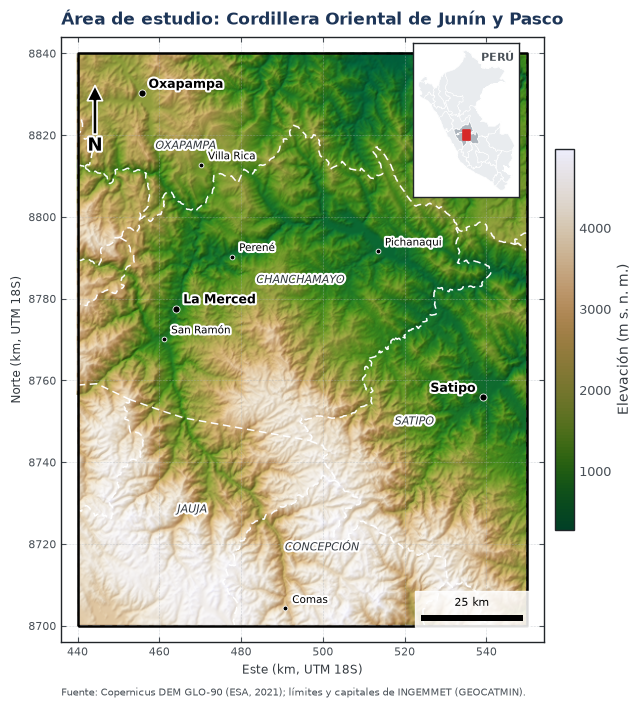

In [10]:
'''Figura 1: el área de estudio sobre el relieve'''

fig, ax = plt.subplots(figsize=(7.5, 9))

'''Elevación en color con el relieve sombreado'''
colores_elev = graf.mapa_hipsometrico(ax, elevacion, extension)

'''Límites provinciales (cada borde se dibuja una sola vez)'''
graf.limites(ax, provincias.clip(aoi.buffer(4000).envelope), color='white', lw=1.1, ls=(0, (5, 3)), zorder=5)

'''Nombre de cada provincia'''
for punto, nombre in zip(prov_aoi.representative_point(), prov_aoi.nombre):
    ax.text(
        punto.x, punto.y, nombre,
        fontsize=8, fontstyle='italic', color='#343a40', ha='center',
        path_effects=graf.HALO, zorder=8,
    )

'''Capitales de provincia (negrita) y de distrito'''
graf.rotular_lugares(ax, provinciales, 'nombre', aoi, tamano=9, marcador=26)
graf.rotular_lugares(ax, distritales, 'nombre', aoi, tamano=7.5, negrita=False, marcador=12)

'''Mapa de ubicación en la esquina superior derecha'''
ubicacion = ax.inset_axes([0.70, 0.735, 0.28, 0.255], zorder=45)
graf.mapa_ubicacion(ubicacion, departamentos, aoi)

'''Barra de color y marco del mapa'''
barra = fig.colorbar(colores_elev, ax=ax, shrink=0.55, pad=0.02)
barra.set_label('Elevación (m s. n. m.)')
graf.marco_mapa(ax, aoi, 'Área de estudio: Cordillera Oriental de Junín y Pasco')
graf.fuente_al_pie(ax, 'Fuente: Copernicus DEM GLO-90 (ESA, 2021); límites y capitales de INGEMMET (GEOCATMIN).')

graf.guardar(fig, 'GC01_01_area_estudio.png')

**Lectura:** el área abarca la transición entre los Andes y la selva: supera los 4000 m al suroeste y desciende por
debajo de 1000 m en los valles de Chanchamayo y Satipo. Este contraste es relevante para la gravedad, ya que la
corrección de Bouguer depende de la topografía; un modelo con topografía suavizada tenderá a errar más donde el
relieve cambia con rapidez.

***

<a id="parte-6"></a>

## <span style="color:#e8761a">**6. VARIABLE 1: ANOMALÍA DE BOUGUER (DOS FUENTES)**</span>
***

| | Estaciones de INGEMMET | Modelo XGM2019e |
|---|---|---|
| Qué es | Gravedad medida con gravímetro en el terreno, corregida a anomalía de Bouguer | Modelo global en armónicos esféricos (grado 2190) que combina satélites, gravedad terrestre y topografía (Zingerle et al., 2020) |
| Formato | Puntos (Shapefile) | Grilla (GeoTIFF), paso de 0,025° (~2,8 km) |
| Resolución real | Puntual | ~9 km (la grilla es más fina que el modelo) |
| Ventaja | Es la medida directa | Cubre toda el área, sin huecos |
| Limitación | 192 puntos, casi todos en carreteras | Bouguer simple (sin corrección de terreno) y topografía suavizada |

Lectura de las estaciones. `lectura.cargar_gravedad_estaciones` renombra los campos originales (`BOUG_MGAL`,
`GRAV_MGAL`) con nombres descriptivos:

In [11]:
'''Estaciones gravimétricas de INGEMMET'''
estaciones = lectura.cargar_gravedad_estaciones()
estaciones.head()

,OBJECTID,bouguer_mgal,gravedad_mgal,geometry
0,2623,-190.35,977929.61,POINT (528235.299 8778995.828)
1,2848,-250.94,977557.65,POINT (519011.684 8728120.485)
2,2926,-185.52,977902.69,POINT (534908.157 8771267.713)
3,2927,-323.26,977723.37,POINT (458323.807 8769269.398)
4,2935,-334.30,977639.87,POINT (456942.043 8768217.137)


Características de la grilla del modelo:

In [12]:
with rasterio.open(ARCHIVOS['gravedad_xgm2019e']) as src:
    print(f'Nodos: {src.width} × {src.height}')
    print(f'Paso: {src.res[0]}°')
    print(f'CRS: {src.crs}')

Nodos: 53 × 63
Paso: 0.025°
CRS: EPSG:4326


Para comparar los valores de ambas fuentes, el modelo se reproyecta a UTM (celdas de 1 km) y se conservan los nodos
dentro del área:

In [13]:
'''Modelo en UTM, solo dentro del área (margen 0)'''
xgm_utm, ext_xgm = espacial.raster_a_utm(ARCHIVOS['gravedad_xgm2019e'], aoi, celda=1000, margen=0)

'''Estadística descriptiva de cada fuente'''
resumen_gravedad = pd.DataFrame({
    'Estaciones de INGEMMET': estaciones.bouguer_mgal.describe(),
    'Modelo XGM2019e (área)': pd.Series(xgm_utm[np.isfinite(xgm_utm)]).describe(),
}).T

resumen_gravedad.rename(columns={'count': 'n', 'mean': 'media', 'std': 'desv. est.', 'min': 'mín.', 'max': 'máx.'})

,n,media,desv. est.,mín.,25%,50%,75%,máx.
Estaciones de INGEMMET,192.0,-259.66,49.63,-368.49,-286.96,-260.62,-215.93,-176.39
Modelo XGM2019e (área),15400.0,-215.17,69.69,-421.57,-260.67,-200.77,-167.86,-65.39


Ambas fuentes se representan lado a lado con la misma escala de color; el modelo incluye curvas cada 50 mGal:

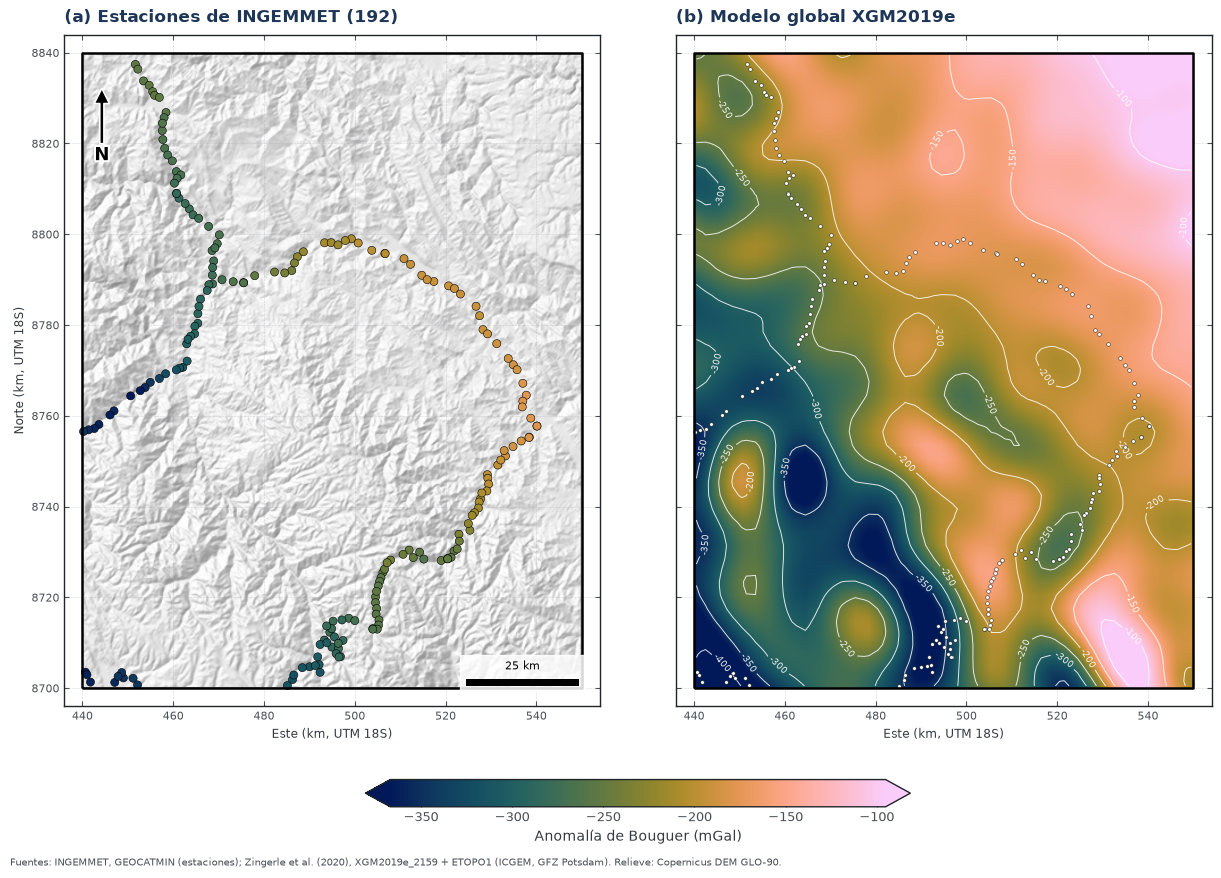

In [14]:
'''Figura 2: las dos fuentes de la anomalía de Bouguer'''

'''Misma escala de color para las dos (percentiles 2 y 98 de ambas fuentes)'''
v_min, v_max = np.nanpercentile(np.r_[estaciones.bouguer_mgal, xgm_utm.ravel()], [2, 98])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 8.4), sharey=True, layout='constrained')

'''(a) Estaciones medidas en el terreno'''
graf.relieve(ax1, elevacion, extension, opacidad=0.55)
estaciones.plot(
    ax=ax1, column='bouguer_mgal', cmap=graf.CMAP_CONTINUO, vmin=v_min, vmax=v_max,
    markersize=34, edgecolor='black', linewidth=0.4, zorder=10,
)
graf.marco_mapa(ax1, aoi, f'(a) Estaciones de INGEMMET ({len(estaciones)})')

'''(b) Modelo global, con el relieve encima y curvas cada 50 mGal'''
im = ax2.imshow(
    xgm_utm, extent=ext_xgm, cmap=graf.CMAP_CONTINUO, vmin=v_min, vmax=v_max,
    interpolation='bilinear', zorder=1,
)
graf.relieve(ax2, elevacion, extension, opacidad=0.18)
x = np.linspace(ext_xgm[0] + 500, ext_xgm[1] - 500, xgm_utm.shape[1])
y = np.linspace(ext_xgm[3] - 500, ext_xgm[2] + 500, xgm_utm.shape[0])
curvas = ax2.contour(
    x, y, xgm_utm, levels=np.arange(-400, -50, 50),
    colors='white', linewidths=0.7, linestyles='solid', alpha=0.85, zorder=2,
)
ax2.clabel(curvas, fmt='%d', fontsize=6.5)
estaciones.plot(ax=ax2, color='white', edgecolor='black', linewidth=0.3, markersize=7, zorder=10)
graf.marco_mapa(ax2, aoi, '(b) Modelo global XGM2019e', accesorios=False)
ax2.set_ylabel('')

'''Una sola barra de color para los dos paneles'''
barra = fig.colorbar(im, ax=[ax1, ax2], orientation='horizontal', shrink=0.45, extend='both')
barra.set_label('Anomalía de Bouguer (mGal)')
graf.fuente_figura(fig, 'Fuentes: INGEMMET, GEOCATMIN (estaciones); Zingerle et al. (2020), XGM2019e_2159 + ETOPO1 '
                   '(ICGEM, GFZ Potsdam). Relieve: Copernicus DEM GLO-90.')

graf.guardar(fig, 'GC01_02_bouguer_dos_fuentes.png')

**Lectura:** ambas fuentes muestran el mismo patrón regional: los valores más negativos se ubican bajo la cordillera,
al oeste, donde la corteza es más gruesa, y aumentan hacia la selva, al este.

Las estaciones siguen la red vial (Tarma - La Merced - Satipo y el valle del Perené), por lo que amplias zonas
carecen de mediciones. El modelo cubre esos vacíos, aunque con una resolución efectiva de unos 9 km.

Para comparar ambas fuentes en los mismos puntos, el modelo se interpola en cada estación con
`espacial.muestrear_raster`.

> La interpolación bilineal pondera los cuatro nodos vecinos del modelo según su distancia a la estación.

In [15]:
'''Valor del modelo en cada estación y diferencia modelo - estación'''
estaciones['xgm_mgal'] = espacial.muestrear_raster(ARCHIVOS['gravedad_xgm2019e'], estaciones)
estaciones['dif_mgal'] = estaciones.xgm_mgal - estaciones.bouguer_mgal

'''Elevación de cada estación (DEM de 90 m), para ver si la diferencia depende del relieve'''
estaciones['elevacion_m'] = espacial.muestrear_raster(ARCHIVOS['dem_90m'], estaciones)

estaciones[['bouguer_mgal', 'xgm_mgal', 'dif_mgal', 'elevacion_m']].head()

,bouguer_mgal,xgm_mgal,dif_mgal,elevacion_m
0,-190.35,-168.76,21.59,658.12
1,-250.94,-262.83,-11.89,2275.42
2,-185.52,-164.42,21.10,744.66
3,-323.26,-322.42,0.84,905.15
4,-334.30,-331.15,3.15,1058.60


El grado de acuerdo se cuantifica con `estadistica.metricas_acuerdo`:
- `sesgo`: diferencia promedio (error sistemático);
- `desv` y `rms`: dispersión de la diferencia (error típico);
- `r` y `rho`: correlación de Pearson y de Spearman;
- `pendiente` e `intercepto` de la recta modelo ~ estación.

In [16]:
acuerdo = estadistica.metricas_acuerdo(estaciones.bouguer_mgal, estaciones.xgm_mgal)
pd.Series(acuerdo, name='modelo frente a estación').to_frame().T

,n,sesgo,desv,rms,r,rho,pendiente,intercepto
modelo frente a estación,192.0,12.03,43.15,44.69,0.8,0.81,1.15,52.23


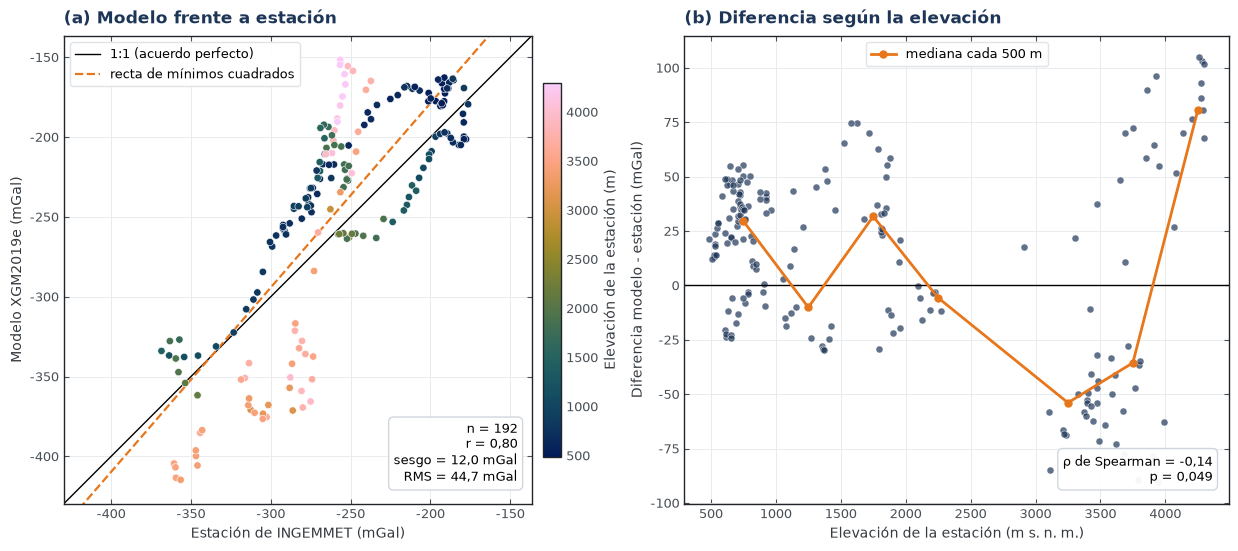

In [17]:
'''Figura 3: (a) diagrama 1:1 entre las fuentes y (b) diferencia según la elevación de la estación'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.4), layout='constrained')

'''(a) Si las fuentes coincidieran, todos los puntos caerían sobre la diagonal 1:1'''
lim = np.array([
    estaciones[['bouguer_mgal', 'xgm_mgal']].min().min() - 15,
    estaciones[['bouguer_mgal', 'xgm_mgal']].max().max() + 15,
])
ax1.plot(lim, lim, color='black', lw=1, label='1:1 (acuerdo perfecto)')
ax1.plot(
    lim, acuerdo['intercepto'] + acuerdo['pendiente'] * lim,
    color=graf.NARANJA, lw=1.6, ls='--', label='recta de mínimos cuadrados',
)
puntos = ax1.scatter(
    estaciones.bouguer_mgal, estaciones.xgm_mgal, c=estaciones.elevacion_m, cmap='cmc.batlow',
    s=28, edgecolor='white', lw=0.4, zorder=3,
)
ax1.set(xlim=lim, ylim=lim, xlabel='Estación de INGEMMET (mGal)', ylabel='Modelo XGM2019e (mGal)')
ax1.set_aspect('equal')
ax1.legend(loc='upper left')
graf.cuadro_texto(
    ax1,
    f'n = {acuerdo["n"]}\n'
    f'r = {graf.numero_es(acuerdo["r"], 2)}\n'
    f'sesgo = {graf.numero_es(acuerdo["sesgo"])} mGal\n'
    f'RMS = {graf.numero_es(acuerdo["rms"])} mGal',
)
fig.colorbar(puntos, ax=ax1, shrink=0.8, pad=0.02, label='Elevación de la estación (m)')
ax1.set_title('(a) Modelo frente a estación')

'''(b) Diferencia frente a elevación, con la mediana por tramos de 500 m'''
rho, p = stats.spearmanr(estaciones.elevacion_m, estaciones.dif_mgal)
tramo = (estaciones.elevacion_m // 500) * 500 + 250
mediana = estaciones.groupby(tramo).dif_mgal.agg(['median', 'size']).query('size >= 5')

ax2.axhline(0, color='black', lw=1)
ax2.scatter(estaciones.elevacion_m, estaciones.dif_mgal, s=26, color=graf.AZUL, alpha=0.7, edgecolor='white', lw=0.5)
ax2.plot(mediana.index, mediana['median'], color=graf.NARANJA, lw=2, marker='o', ms=5, label='mediana cada 500 m')
ax2.set(xlabel='Elevación de la estación (m s. n. m.)', ylabel='Diferencia modelo - estación (mGal)')
ax2.legend(loc='upper center')
graf.cuadro_texto(ax2, f'ρ de Spearman = {graf.numero_es(rho, 2)}\n{graf.texto_p(p)}')
ax2.set_title('(b) Diferencia según la elevación')

for ax in (ax1, ax2):
    graf.ejes_coma_decimal(ax)

graf.guardar(fig, 'GC01_03_bouguer_comparacion.png', svg=True)

En la figura 3b, las estaciones situadas por encima de 3000 m forman dos grupos con diferencias de signo opuesto. Se
separan para localizarlos:

In [18]:
'''Estaciones altas (> 3000 m) donde el modelo da más o da menos que la estación'''
alto = estaciones.elevacion_m > 3000
grupos = {
    'el modelo da más': estaciones[alto & (estaciones.dif_mgal > 0)],
    'el modelo da menos': estaciones[alto & (estaciones.dif_mgal < 0)],
}

pd.DataFrame({
    nombre: {
        'estaciones': len(g),
        'diferencia mín. (mGal)': g.dif_mgal.min(),
        'diferencia máx. (mGal)': g.dif_mgal.max(),
        'este medio (km)': g.geometry.x.median() / 1000,
        'norte medio (km)': g.geometry.y.median() / 1000,
    }
    for nombre, g in grupos.items()
}).T

,estaciones,diferencia mín. (mGal),diferencia máx. (mGal),este medio (km),norte medio (km)
el modelo da más,22.0,10.61,104.93,505.28,8721.92
el modelo da menos,35.0,-90.58,-11.00,492.35,8706.86


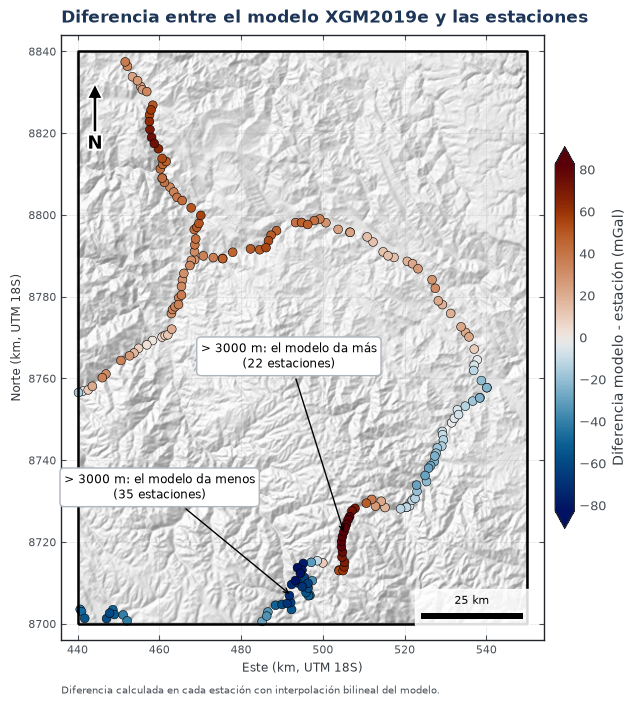

In [19]:
'''Figura 4: dónde el modelo se aleja de las estaciones (azul: el modelo da menos; rojo: da más)'''

fig, ax = plt.subplots(figsize=(7.5, 9))
graf.relieve(ax, elevacion, extension, opacidad=0.6)

'''Escala simétrica: el 95 % de las diferencias queda dentro de ±limite'''
limite = np.nanpercentile(np.abs(estaciones.dif_mgal), 95)

'''Las diferencias grandes se dibujan al final, encima de las pequeñas'''
estaciones.sort_values('dif_mgal', key=np.abs).plot(
    ax=ax, column='dif_mgal', cmap=graf.CMAP_DIVERGENTE, norm=TwoSlopeNorm(0, -limite, limite),
    markersize=40, edgecolor='black', linewidth=0.4, zorder=10, legend=True,
    legend_kwds={'label': 'Diferencia modelo - estación (mGal)', 'shrink': 0.55, 'pad': 0.02, 'extend': 'both'},
)

'''Señalamos los dos grupos de estaciones altas'''
for (nombre, g), desplazamiento in zip(grupos.items(), [(-40, 120), (-95, 70)]):
    ax.annotate(
        f'> 3000 m: {nombre}\n({len(g)} estaciones)', (g.geometry.x.median(), g.geometry.y.median()),
        xytext=desplazamiento, textcoords='offset points', ha='center', fontsize=8.5,
        bbox=dict(boxstyle='round,pad=0.35', fc='white', ec='#adb5bd'),
        arrowprops=dict(arrowstyle='->', color='black', lw=1), zorder=45,
    )

graf.marco_mapa(ax, aoi, 'Diferencia entre el modelo XGM2019e y las estaciones')
graf.fuente_al_pie(ax, 'Diferencia calculada en cada estación con interpolación bilineal del modelo.')

graf.guardar(fig, 'GC01_04_bouguer_diferencia.png')

**Lectura (preliminar; el análisis completo corresponde a GC02):** ambas fuentes están bien correlacionadas
(r = 0,80), de modo que el modelo reproduce el patrón regional. Sin embargo, no son intercambiables: el modelo supera
en promedio en 12 mGal a las estaciones y su error típico (RMS) es de 44,7 mGal, por lo que no puede reemplazar a
las mediciones a escala local.

La diferencia tampoco depende de forma simple de la elevación (ρ = -0,14). Las estaciones altas se dividen en dos
grupos de signo opuesto que, en el mapa, corresponden a tramos de carretera vecinos al sur del área. Un error
atribuible solo al modelo no produciría diferencias de signo contrario en tramos tan próximos; por ello, la primera
hipótesis para GC02 es que también influye la campaña de medición (una referencia o una corrección distinta).

Se suman tres causas esperables:
1. la resolución efectiva del modelo (~9 km frente a una medición puntual);
2. la ausencia de corrección de terreno en la anomalía de Bouguer simple, que en los Andes puede superar 20 a 50 mGal;
3. sobre los continentes, por encima del grado 719, el modelo emplea gravedad derivada de la topografía y no gravedad
   medida (Zingerle et al., 2020).

***

<a id="parte-7"></a>

## <span style="color:#e8761a">**7. VARIABLE 2: URANIO EN ROCA (CINCO FUENTES)**</span>
***

Cada fuente tiene su propia estructura de columnas; `lectura.cargar_uranio` las integra en una tabla común.

La química se publica como texto y se convierte a números con reglas explícitas (`lectura.leer_valor`):
- `'<2.00'` está por debajo del límite de detección: no equivale a 2 ni a 0;
- `'########'` corresponde a un valor perdido en la fuente;
- `0` en una roca indica que el elemento no se determinó.

> Se excluyen los 3 suelos del GE27 y la muestra de torbernita del IPEN, que no son rocas.

In [20]:
'''Tabla común de U en roca con las cinco fuentes'''
uranio = lectura.cargar_uranio()
uranio.head()

,fuente,codigo,U_ppm,estado_U,Th_ppm,SiO2_pct,anio,metodo,es_mena,geometry
0,Litogeoquímica,SU-03-24,2.80,numero,23.90,65.43,2009.0,fusión (mayoritaria),False,POINT (443513.107 8757945.028)
1,Litogeoquímica,OX05,4.90,numero,8.15,60.90,1991.0,fusión (mayoritaria),False,POINT (458432.09 8828222.824)
2,Litogeoquímica,GR6-0966,4.76,numero,18.50,75.45,NaN,fusión (mayoritaria),False,POINT (466954.896 8787628.452)
3,Litogeoquímica,GR6-09-137_ra,1.55,numero,14.80,74.20,NaN,fusión (mayoritaria),False,POINT (445718.219 8827145.661)
4,Litogeoquímica,SV-M44,NaN,cero,NaN,NaN,1990.0,fusión (mayoritaria),False,POINT (461790.441 8761883.659)


Estado del dato de U en cada fuente:

In [21]:
pd.crosstab(uranio.fuente, uranio.estado_U, margins=True, margins_name='total').loc[lectura.FUENTES_U + ['total']]

estado_U,<LD,cero,numero,vacio,total
fuente,,,,,
Litogeoquímica,0,26,330,2,358
BDG 2022,3,0,234,144,381
GE27,0,0,45,0,45
IPEN,0,0,19,0,19
B-74,0,0,7,0,7
total,3,26,635,146,810


La comparación se restringe al U medido y excluye las muestras de mena (Cu, Pb o Zn > 1000 ppm), que no representan
a la roca de caja.

> Solo la litogeoquímica y BDG 2022 analizan esos metales; en las demás fuentes el filtro no es aplicable.

In [22]:
'''Rocas con U medido y sin mena'''
u_roca = uranio[uranio.U_ppm.notna() & ~uranio.es_mena]
print('Muestras de mena excluidas:', uranio[uranio.es_mena].fuente.value_counts().to_dict())

'''Resumen del U por fuente'''
resumen_u = estadistica.resumen_por_grupo(u_roca, 'U_ppm', 'fuente', orden=lectura.FUENTES_U)
resumen_u = resumen_u.drop(columns='n_total').rename(columns={'n_medido': 'n'})

'''Años y método analítico de cada fuente'''
por_fuente = u_roca.groupby('fuente')
resumen_u['años'] = por_fuente.anio.agg(lambda a: f'{a.min():.0f}-{a.max():.0f}' if a.notna().any() else '-')
resumen_u['método'] = por_fuente.metodo.agg(lambda m: ', '.join(sorted(m.unique())))
resumen_u

Muestras de mena excluidas: {'BDG 2022': 27, 'Litogeoquímica': 3}


,n,mediana,P25,P75,min,max,años,método
fuente,,,,,,,,
Litogeoquímica,327,3.60,1.70,6.15,0.10,37.40,1991-2009,fusión (mayoritaria)
BDG 2022,208,4.00,2.40,6.85,0.20,76.70,2018-2024,"digestión parcial, digestión total, fusión"
GE27,45,3.48,1.80,6.90,0.21,233.67,2012-2012,fusión (peróxido de sodio)
IPEN,19,15.50,11.15,81.00,3.50,280.00,2013-2016,"AAN, No declarado (química)"
B-74,7,2.90,1.80,7.20,0.50,50.80,2021-2021,digestión sin HF


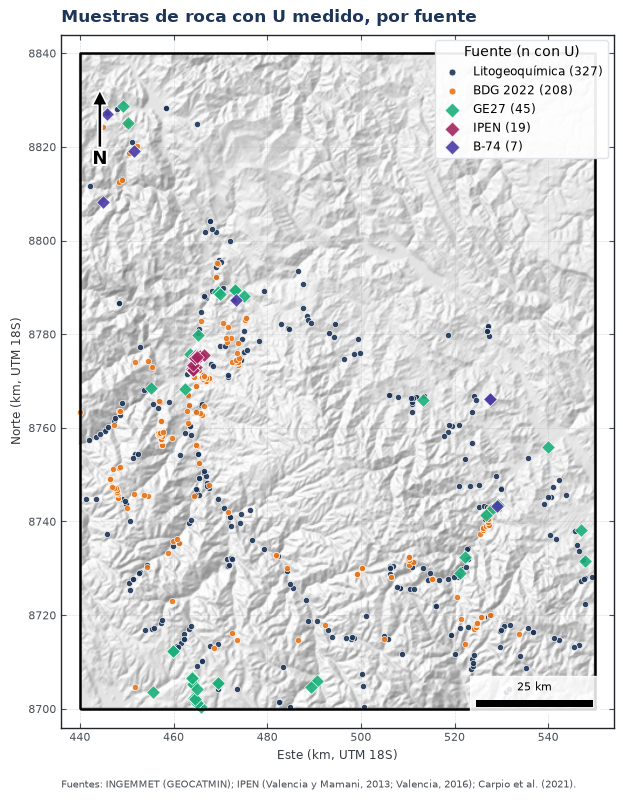

In [23]:
'''Figura 5: dónde muestreó cada fuente'''

fig, ax = plt.subplots(figsize=(7.5, 9))
graf.relieve(ax, elevacion, extension, opacidad=0.6)

'''Las fuentes con pocas muestras van con puntos más grandes, encima de las demás'''
for fuente in lectura.FUENTES_U:
    t = u_roca[u_roca.fuente == fuente]
    t.plot(
        ax=ax, color=graf.COLORES_FUENTE[fuente], markersize=20 if len(t) > 50 else 48,
        marker='o' if len(t) > 50 else 'D', edgecolor='white', linewidth=0.5, alpha=0.9, zorder=10,
        label=f'{fuente} ({len(t)})',
    )

ax.legend(loc='upper right', title='Fuente (n con U)', fontsize=8.5, markerscale=1.1).set_zorder(50)
graf.marco_mapa(ax, aoi, 'Muestras de roca con U medido, por fuente')
graf.fuente_al_pie(ax, 'Fuentes: INGEMMET (GEOCATMIN); IPEN (Valencia y Mamani, 2013; Valencia, 2016); Carpio et al. (2021).')

graf.guardar(fig, 'GC01_05_uranio_mapa_fuentes.png')

Distribución del U por fuente, en escala logarítmica dado que la concentración varía en órdenes de magnitud. La
referencia es la corteza continental superior (2,7 ppm; Rudnick y Gao, 2003):

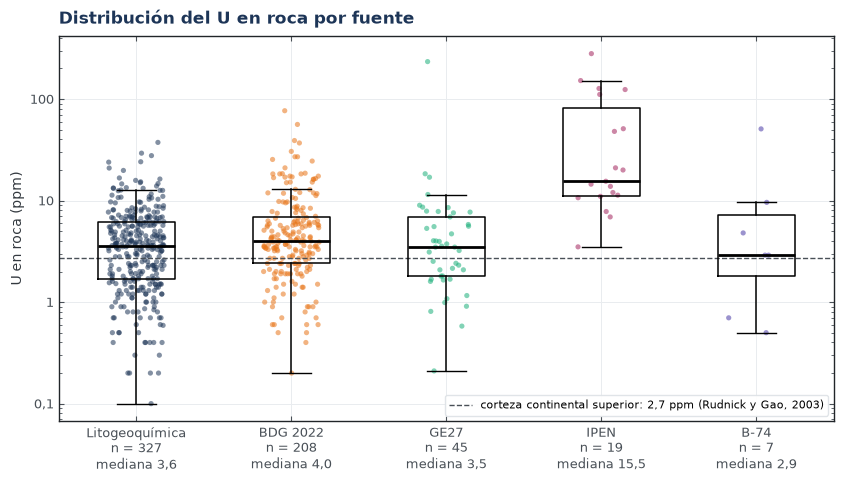

In [24]:
'''Figura 6: distribución del U por fuente'''

fig, ax = plt.subplots(figsize=(10, 5))
rng = np.random.default_rng(0)                  # dispersión horizontal reproducible

for i, fuente in enumerate(lectura.FUENTES_U):
    v = u_roca.loc[u_roca.fuente == fuente, 'U_ppm']
    '''Cada muestra como un punto, separados un poco a los lados'''
    ax.scatter(
        i + rng.uniform(-0.18, 0.18, len(v)), v,
        s=14, color=graf.COLORES_FUENTE[fuente], alpha=0.55, edgecolor='none', zorder=2,
    )
    '''Caja con la mediana y los cuartiles'''
    ax.boxplot(
        v, positions=[i], widths=0.5, showfliers=False, zorder=3,
        medianprops=dict(color='black', lw=2), boxprops=dict(lw=1.1), whiskerprops=dict(lw=1.1),
    )

'''Referencia: corteza continental superior'''
ax.axhline(2.7, color=graf.GRIS, ls='--', lw=1, label='corteza continental superior: 2,7 ppm (Rudnick y Gao, 2003)')
ax.legend(loc='lower right', fontsize=8)

'''Rótulos: fuente, número de muestras y mediana'''
rotulos = [
    f'{f}\nn = {(u_roca.fuente == f).sum()}\nmediana {graf.numero_es(u_roca.loc[u_roca.fuente == f, "U_ppm"].median())}'
    for f in lectura.FUENTES_U
]
ax.set_xticks(range(len(lectura.FUENTES_U)), rotulos)
ax.set_yscale('log')
ax.set_ylabel('U en roca (ppm)')
ax.set_title('Distribución del U en roca por fuente')
graf.ejes_coma_decimal(ax, x=False)

graf.guardar(fig, 'GC01_06_uranio_distribucion_fuentes.png', svg=True)

Como primera comparación directa se buscan pares de muestras de dos fuentes separadas por menos de 250 m, que en la
práctica corresponden al mismo afloramiento. `espacial.pares_cercanos` emplea cada muestra una sola vez, de modo que
una roca atípica no pese varias veces.

> La comparación usa la razón B/A y no la diferencia, porque en geoquímica el error analítico es proporcional al
> valor.

In [25]:
'''Pares de muestras cercanas entre cada combinación de fuentes'''
pares = []
for i, a in enumerate(lectura.FUENTES_U):
    for b in lectura.FUENTES_U[i + 1:]:
        p = espacial.pares_cercanos(u_roca[u_roca.fuente == a], u_roca[u_roca.fuente == b], distancia_max=250)
        if len(p) == 0:
            continue
        r = estadistica.comparar_pares_log(u_roca.loc[p.i_a, 'U_ppm'], u_roca.loc[p.i_b, 'U_ppm'])
        pares.append({
            'fuente A': a,
            'fuente B': b,
            'pares': r['n'],
            'distancia mediana (m)': p.dist_m.median(),
            'razón mediana B/A': r['razon_mediana'],
            'p de Wilcoxon': r['p_wilcoxon'],
        })

pd.DataFrame(pares)

,fuente A,fuente B,pares,distancia mediana (m),razón mediana B/A,p de Wilcoxon
0,Litogeoquímica,BDG 2022,16,89.92,1.34,0.07
1,Litogeoquímica,GE27,3,82.09,0.65,NaN
2,Litogeoquímica,IPEN,1,119.97,1.86,NaN
3,Litogeoquímica,B-74,1,40.65,3.10,NaN
4,BDG 2022,GE27,5,10.20,0.94,0.62
5,BDG 2022,IPEN,1,149.09,34.15,NaN
6,GE27,IPEN,1,2.83,16.78,NaN


**Lectura (preliminar; la validación corresponde a GC02):** la litogeoquímica, BDG 2022, GE27 y B-74 presentan
medianas similares, de 3 a 4 ppm, próximas al promedio de la corteza superior, como corresponde a muestreos
regionales.

La mediana del IPEN es unas cuatro veces mayor. La diferencia no se atribuye al laboratorio: el IPEN muestreó
deliberadamente el granito de San Ramón, donde ya se conocían indicios de uranio. Se trata de un sesgo de muestreo;
estos datos son útiles para validar la zona favorable, pero no para estimar el contenido de fondo de la región.

El único par de fuentes con datos suficientes es litogeoquímica frente a BDG 2022 (16 pares): razón mediana de 1,3 y
p de Wilcoxon de 0,07, diferencia no significativa al 5 %. Con 16 pares la prueba tiene baja potencia; en GC02 la
comparación se separará por método analítico, ya que BDG combina digestión total y parcial. Las demás combinaciones
reúnen entre 1 y 5 pares y tienen valor ilustrativo.

***

<a id="parte-8"></a>

## <span style="color:#e8761a">**8. VARIABLES PARA EL ANÁLISIS DE RELACIÓN**</span>
***

La pregunta 3 relaciona el U con:
- el **torio**, porque ambos se concentran conjuntamente durante la diferenciación magmática, aunque el U es más
  móvil durante la alteración;
- el **SiO₂**, porque el U se acumula en los granitos más evolucionados;
- el **berilio de los sedimentos de quebrada**, que procede de la erosión de esos mismos granitos.

En este avance se verifica la disponibilidad de datos y una primera tendencia; el análisis completo corresponde a
GC03.

In [26]:
'''Sedimentos de quebrada (Be, La, Y)'''
sedimentos = lectura.cargar_sedimentos()
print(f'Sedimentos: {len(sedimentos)}')
print(f'Con Be: {sedimentos.Be_ppm.notna().sum()} | con La: {sedimentos.La_ppm.notna().sum()} | con Y: {sedimentos.Y_ppm.notna().sum()}')

'''Rocas con U y Th, y con U y SiO2'''
u_th = u_roca.dropna(subset=['Th_ppm'])
u_si = u_roca.dropna(subset=['SiO2_pct'])
print(f'Rocas con U y Th: {len(u_th)} | con U y SiO₂: {len(u_si)}')

Sedimentos: 720
Con Be: 591 | con La: 720 | con Y: 720
Rocas con U y Th: 560 | con U y SiO₂: 455


Relación del U con el Th y con el SiO₂. Se emplea la correlación de Spearman, basada en rangos, que no supone una
relación lineal. El panel del Th incluye la razón Th/U de la corteza superior (10,5 / 2,7 = 3,9; Rudnick y Gao,
2003):

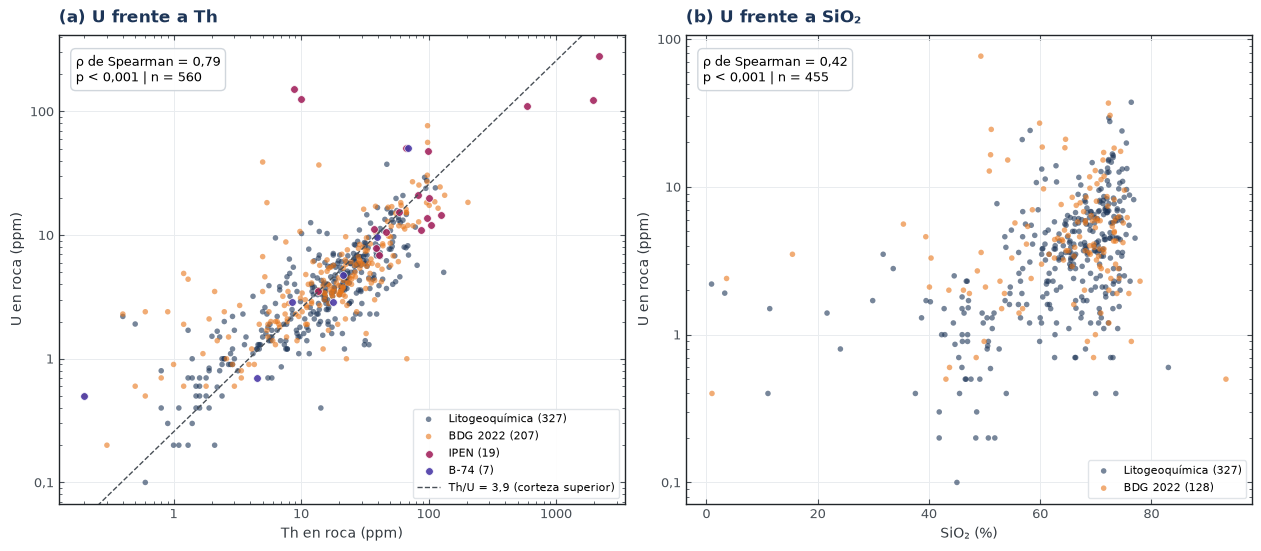

In [27]:
'''Figura 7: primeras relaciones del U con el Th y con el SiO2'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12.5, 5.4), layout='constrained')
paneles = [
    (ax1, u_th, 'Th_ppm', 'Th en roca (ppm)', '(a) U frente a Th'),
    (ax2, u_si, 'SiO2_pct', 'SiO₂ (%)', '(b) U frente a SiO₂'),
]

for ax, tabla, columna, etiqueta, titulo in paneles:
    '''Puntos por fuente (las de muchas muestras primero, para que las pequeñas queden encima)'''
    for fuente in lectura.FUENTES_U:
        t = tabla[tabla.fuente == fuente]
        if len(t):
            ax.scatter(
                t[columna], t.U_ppm, s=16 if len(t) > 50 else 30, alpha=0.6 if len(t) > 50 else 0.9,
                color=graf.COLORES_FUENTE[fuente], edgecolor='none' if len(t) > 50 else 'white', lw=0.5,
                label=f'{fuente} ({len(t)})',
            )
    rho, p = stats.spearmanr(tabla[columna], tabla.U_ppm)
    graf.cuadro_texto(
        ax, f'ρ de Spearman = {graf.numero_es(rho, 2)}\n{graf.texto_p(p)} | n = {len(tabla)}',
        x=0.03, y=0.96, ha='left', va='top',
    )
    ax.set_yscale('log')
    ax.set(xlabel=etiqueta, ylabel='U en roca (ppm)', title=titulo)

'''Razón Th/U de la corteza superior'''
ax1.set_xscale('log')
x_lim, y_lim = ax1.get_xlim(), ax1.get_ylim()
th = np.logspace(-1, 3.5, 50)
ax1.plot(th, th / 3.9, color=graf.GRIS, ls='--', lw=1, label='Th/U = 3,9 (corteza superior)')
ax1.set(xlim=x_lim, ylim=y_lim)

for ax in (ax1, ax2):
    ax.legend(loc='lower right', fontsize=8)
    graf.ejes_coma_decimal(ax)

graf.guardar(fig, 'GC01_07_uranio_relaciones.png', svg=True)

**Lectura:** el U y el Th presentan una relación fuerte (ρ = 0,79), coherente con su comportamiento conjunto en el
magma, y la mayoría de las rocas se sitúa cerca de la razón de la corteza. Con el SiO₂ la relación es moderada
(ρ = 0,42): el U aumenta en las rocas más silíceas, con una dispersión considerable. Los cientos de pares disponibles
son suficientes para el análisis de GC03.

***

<a id="parte-9"></a>

## <span style="color:#e8761a">**9. COBERTURA ESPACIAL Y PERIODO DE LOS DATOS**</span>
***

El número de muestras no basta para evaluar la cobertura: cien muestras en una sola quebrada cubren muy poco. Por
ello, el área se divide en celdas de 5 × 5 km y se cuenta cuántas contienen al menos un dato de cada fuente
(`espacial.cobertura`).

In [28]:
'''Capas que vamos a evaluar'''
capas = {f'U - {f}': u_roca[u_roca.fuente == f] for f in lectura.FUENTES_U}
capas['U - todas las fuentes'] = u_roca
capas['Bouguer - estaciones'] = estaciones
capas['Be - sedimentos'] = sedimentos[sedimentos.Be_ppm.notna()]

'''Porcentaje de celdas de 5 km con al menos un dato'''
cobertura = pd.concat({
    nombre: espacial.cobertura(capa, aoi, celda=5000).iloc[0] for nombre, capa in capas.items()
}).unstack()

'''La grilla del modelo de gravedad cubre toda el área'''
n_celdas = len(espacial.grilla(aoi, celda=5000))
cobertura.loc['Bouguer - XGM2019e'] = [np.nan, n_celdas, 100.0]
cobertura

,puntos,celdas_con_dato,cobertura_pct
U - Litogeoquímica,327.0,135.0,21.92
U - BDG 2022,208.0,64.0,10.39
U - GE27,45.0,24.0,3.90
U - IPEN,19.0,3.0,0.49
U - B-74,7.0,6.0,0.97
U - todas las fuentes,606.0,167.0,27.11
Bouguer - estaciones,192.0,74.0,12.01
Be - sedimentos,591.0,266.0,43.18
Bouguer - XGM2019e,NaN,616.0,100.00


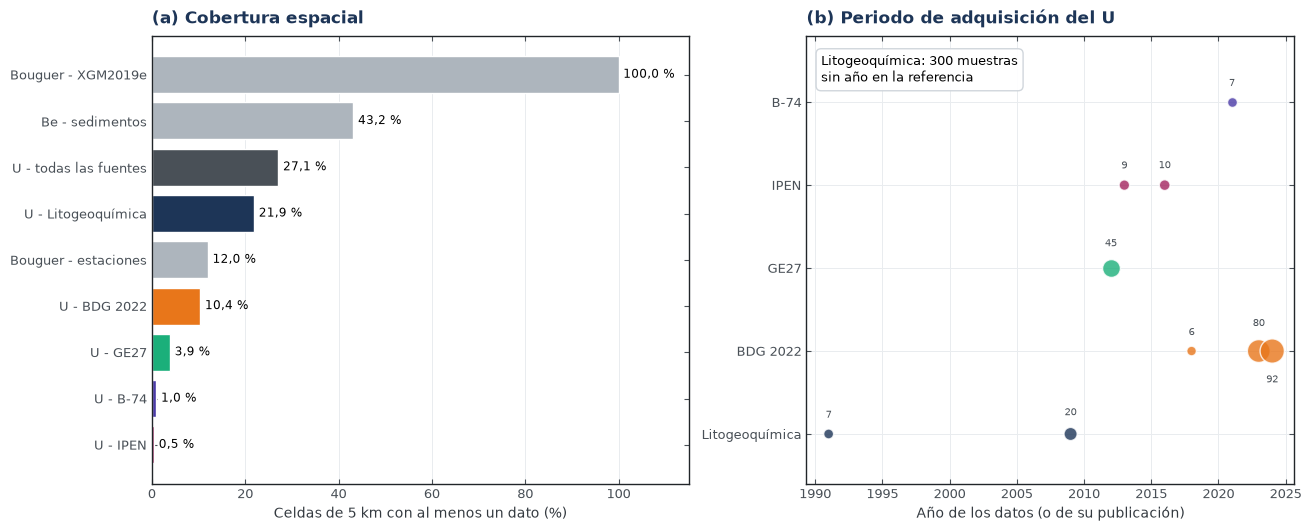

In [29]:
'''Figura 8: (a) cobertura espacial y (b) años de adquisición del U'''

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 5.2), gridspec_kw={'width_ratios': [1.1, 1]}, layout='constrained')

'''(a) Barras ordenadas: U con el color de su fuente, las demás variables en gris'''
orden = cobertura.cobertura_pct.sort_values()
colores = [
    graf.COLORES_FUENTE.get(n.removeprefix('U - '), graf.GRIS) if n.startswith('U - ') else '#adb5bd'
    for n in orden.index
]
ax1.barh(orden.index, orden.values, color=colores, edgecolor='white')
for y, v in enumerate(orden.values):
    ax1.text(v + 1, y, f'{graf.numero_es(v)} %', va='center', fontsize=8.5)
ax1.set(xlim=(0, 115), xlabel='Celdas de 5 km con al menos un dato (%)')
ax1.set_title('(a) Cobertura espacial')
ax1.grid(axis='y', visible=False)

'''(b) Cada burbuja es un año con datos; el número indica cuántas muestras'''
fuentes_tiempo = [f for f in lectura.FUENTES_U if u_roca.loc[u_roca.fuente == f, 'anio'].notna().any()]
for i, fuente in enumerate(fuentes_tiempo):
    conteo = u_roca.loc[u_roca.fuente == fuente, 'anio'].value_counts().sort_index()
    ax2.scatter(
        conteo.index, [i] * len(conteo), s=30 + 3 * conteo.values,
        color=graf.COLORES_FUENTE[fuente], alpha=0.8, edgecolor='white',
    )
    '''Número de muestras: arriba de la burbuja, o abajo si el año anterior está muy cerca'''
    anterior = -np.inf
    for anio, n in conteo.items():
        signo = -1 if anio - anterior < 3 else 1
        ax2.annotate(
            f'{n}', (anio, i), xytext=(0, signo * (11 + np.sqrt(n))), textcoords='offset points',
            ha='center', va='center', fontsize=7.5, color=graf.GRIS,
        )
        anterior = anio

sin_anio = u_roca.loc[u_roca.fuente == 'Litogeoquímica', 'anio'].isna().sum()
ax2.set(yticks=range(len(fuentes_tiempo)), yticklabels=fuentes_tiempo, xlabel='Año de los datos (o de su publicación)')
ax2.set_ylim(-0.6, len(fuentes_tiempo) - 0.2)
ax2.set_title('(b) Periodo de adquisición del U')
graf.cuadro_texto(ax2, f'Litogeoquímica: {sin_anio} muestras\nsin año en la referencia', x=0.03, y=0.96, ha='left', va='top')

graf.guardar(fig, 'GC01_08_cobertura_y_periodo.png', svg=True)

**Lectura:** en el espacio, solo los sedimentos (Be) y el modelo de gravedad cubren el área de forma amplia. Las
rocas y las estaciones gravimétricas son puntuales y se agrupan a lo largo de carreteras y valles; en consecuencia,
la comparación entre fuentes debe realizarse donde ambas coexisten, sin extrapolarla a toda el área.

En el tiempo, los datos de U abarcan de 1991 a 2024: más de tres décadas con laboratorios y métodos distintos
(fusión, digestión total, digestión parcial y activación neutrónica), lo que justifica la validación de las
fuentes.

***

<a id="parte-10"></a>

## <span style="color:#e8761a">**10. CONCLUSIONES Y PRÓXIMOS PASOS**</span>
***

Este avance establece que:
1. Todos los archivos de `datos/` están en el repositorio y coinciden con su huella sha256; GEOCATMIN responde en
   línea con el mismo número de estaciones que la copia local.
2. Se dispone de dos variables con fuentes múltiples: la anomalía de Bouguer (estaciones y modelo global, en
   formatos distintos) y el uranio en roca (cinco fuentes de dos instituciones).
3. Todos los datos se encuentran dentro del área de estudio. El modelo de gravedad y los sedimentos la cubren casi
   por completo; las rocas y las estaciones, solo en parte.
4. El modelo de gravedad reproduce el patrón regional (r = 0,80) con un error típico de 44,7 mGal. El U de las
   fuentes regionales es comparable, y el IPEN presenta un sesgo de muestreo hacia las zonas con indicios.

Trabajo previsto para la entrega final:

| Cuaderno | Alcance | Técnicas |
|---|---|---|
| GC02 - Validación de fuentes | Gravedad: diferencia frente a la rugosidad del relieve, por zonas y con una corrección de terreno aproximada. U: pares por método analítico y por litología | Diferencias, RMS, regresión, Bland-Altman, Wilcoxon |
| GC03 - Relación entre variables | U frente a Th, SiO₂ y Be del sedimento más cercano; gravedad en zonas de U alto frente a U bajo | Spearman, Mann-Whitney, regresión en escala logarítmica |

Limitaciones identificadas:
- No existe radiometría pública (eU, eTh), que constituiría una tercera fuente de U.
- El modelo de gravedad tiene una resolución efectiva de unos 9 km.
- Las muestras de roca no son aleatorias: responden a los accesos y a los objetivos de cada institución.

***

<a id="referencias"></a>

## <span style="color:#e8761a">**REFERENCIAS**</span>
***

- Carpio et al. (2021). [*Prospección del litio en el norte y centro del Perú*](https://hdl.handle.net/20.500.12544/3542) (Boletín B-74). INGEMMET.
- European Space Agency (2021). [*Copernicus Global Digital Elevation Model* (GLO-90)](https://doi.org/10.5069/G9028PQB). Distribuido por OpenTopography.
- Mišković, A., Spikings, R. A., Chew, D. M., Košler, J., Ulianov, A., y Schaltegger, U. (2009). [Tectonomagmatic evolution of Western Amazonia: Geochemical characterization and zircon U-Pb geochronologic constraints from the Peruvian Eastern Cordilleran granitoids](https://doi.org/10.1130/B26488.1). *GSA Bulletin, 121*(9-10), 1298-1324.
- Rudnick, R. L., y Gao, S. (2003). [Composition of the continental crust](https://doi.org/10.1016/B0-08-043751-6/03016-4). En *Treatise on Geochemistry* (vol. 3, pp. 1-64). Elsevier.
- Valencia y Mamani (2013). En *Informe Científico Tecnológico 2011* (pp. 79-84). Instituto Peruano de Energía Nuclear.
- Valencia (2016). En *Informe Científico Tecnológico*, vol. 14 (p. 131). Instituto Peruano de Energía Nuclear.
- Zingerle, P., Pail, R., Gruber, T., y Oikonomidou, X. (2020). [The combined global gravity field model XGM2019e](https://doi.org/10.1007/s00190-020-01398-0). *Journal of Geodesy, 94*, 66.

***